# Лабораторная работа №2: Детекция и сегментация объектов

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Проверить разметку и распределения объектов.
- Дообучить компактный segmentation baseline.
- Сравнить аугментации и проанализировать ошибки.


## Теоретическая часть

В детекции модель предсказывает классы и bounding boxes, в сегментации — метку каждого пикселя. Для класса $c$ качество сегментации измеряет $IoU_c=|P_c\cap G_c|/|P_c\cup G_c|$. Для детекции mAP усредняет AP по классам и порогам IoU.

![Segmentation example](https://pytorch.org/vision/main/_images/sphx_glr_plot_visualization_utils_008.png)


### Математическая постановка

Составная функция потерь может иметь вид
$$\mathcal L=\mathcal L_{cls}+\lambda_{box}\mathcal L_{box}+\lambda_{mask}\mathcal L_{mask}.$$
Разбиение должно выполняться по исходным объектам/сериям, иначе соседние кадры дают утечку.


### Материалы

- [Torchvision segmentation models](https://pytorch.org/vision/stable/models.html#semantic-segmentation)
- [COCO metrics](https://cocodataset.org/#detection-eval)
- [Oxford-IIIT Pet Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Проверить разметку и распределения объектов.
2. Дообучить компактный segmentation baseline.
3. Сравнить аугментации и проанализировать ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** LRASPP-MobileNetV3 или FCN-ResNet50, mixed precision.
- **Ограничение данных:** Oxford-IIIT Pet или до 2 000 изображений; в smoke-режиме — синтетический датасет.
- **Fallback:** замороженный backbone и 256 px.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': '/data'}


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Маски Oxford-IIIT Pet

*Вес: 1 балл.*

**Постановка.** Сегментатор обучается на реальной пиксельной разметке.

Выполните следующие действия:
1. Загрузите trainval Oxford-IIIT Pet и совместно масштабируйте изображение и маску.
2. Убедитесь, что интерполяция маски сохраняет классы.

**Результат.** Датасет ds и преобразования img_tf, mask_tf.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


100%|██████████| 792M/792M [00:22<00:00, 35.5MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 15.3MB/s]


Уникальные значения маски после resize: [1, 2, 3]
Интерполяция маски сохраняет классы (1, 2, 3): True
Форма изображения: torch.Size([3, 256, 256]), форма маски: torch.Size([256, 256])
Изображение и маска масштабируются совместно: True
Датасет: 3680 изображений, размер 256x256


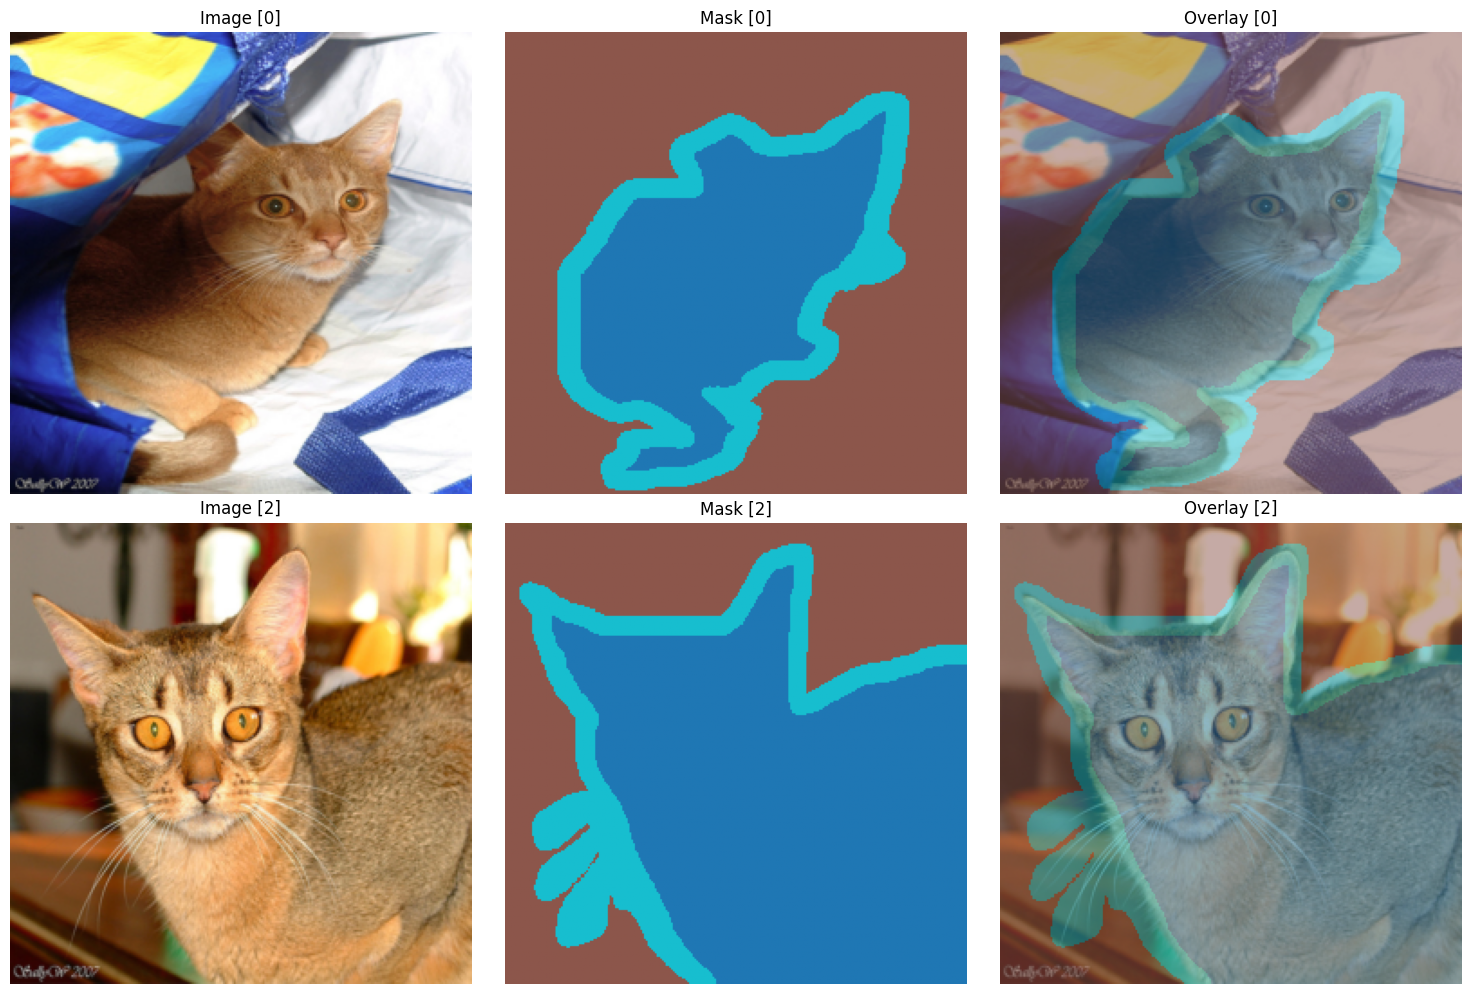


Распределение классов для изображения [0]:
  foreground :  17588 пикселей ( 26.8%)
  background :  38201 пикселей ( 58.3%)
  boundary   :   9747 пикселей ( 14.9%)

Распределение классов для изображения [2]:
  foreground :  34601 пикселей ( 52.8%)
  background :  21043 пикселей ( 32.1%)
  boundary   :   9892 пикселей ( 15.1%)


In [ ]:
from torchvision.datasets import OxfordIIITPet
from torchvision import transforms
from PIL import Image
import torch
import numpy as np
import matplotlib.pyplot as plt

# задача сегментации значит, что мы каждый пиксель изображения относим к классу(1,2,3)
# корень данных для Oxford-IIIT Pet
PET_ROOT = DATA_ROOT / "oxford-iiit-pet"
PET_ROOT.mkdir(parents=True, exist_ok=True)

# загружаем датасет trainval
ds = OxfordIIITPet(
    root=str(PET_ROOT),
    split="trainval",
    target_types="segmentation",
    download=True,
)

# преобразования
IMG_SIZE = 256 if not FAST_DEV_RUN else 128

img_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.BILINEAR), # для картинки BILINEAR, то есть берем среднее значение
    # соседних пикселей (когда делаем интерполяцию, то есть растягиваем картинку до нужного размера)
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

mask_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.NEAREST), # для маски NEAREST, то есть берем старый ближайший пиксель
    # и копируем его, чтобы получить целые номера классов в маске
    transforms.PILToTensor(),
    transforms.Lambda(lambda x: x.squeeze(0).long()),
])

# проверяем что интерполяция маски сохраняет классы
sample_img, sample_mask = ds[0] # берем первое изображение и его маску
sample_mask_t = mask_tf(sample_mask) # применяем resize до 256×256 с NEAREST
unique_vals = torch.unique(sample_mask_t) # собираем значения в маске foreground само животное, background фон, boundary граница/контур животного
print(f"Уникальные значения маски после resize: {unique_vals.tolist()}")

all_in_range = all(v in [1, 2, 3] for v in unique_vals.tolist())
print(f"Интерполяция маски сохраняет классы (1, 2, 3): {all_in_range}")

# проверяем совместное масштабирование
img_t = img_tf(sample_img)
print(f"Форма изображения: {img_t.shape}, форма маски: {sample_mask_t.shape}")
shapes_match = (img_t.shape[1:] == sample_mask_t.shape)
print(f"Изображение и маска масштабируются совместно: {shapes_match}")
print(f"Датасет: {len(ds)} изображений, размер {IMG_SIZE}x{IMG_SIZE}")

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def denormalize(img_t):
    return (img_t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

idxs = [0, 2]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for row, idx in enumerate(idxs):
    img, mask = ds[idx]
    img_t = img_tf(img)
    mask_t = mask_tf(mask)
    img_vis = denormalize(img_t)

    axes[row, 0].imshow(img_vis)
    axes[row, 0].set_title(f"Image [{idx}]")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask_t.numpy(), cmap="tab10", vmin=1, vmax=3)
    axes[row, 1].set_title(f"Mask [{idx}]")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(img_vis)
    axes[row, 2].imshow(mask_t.numpy(), cmap="tab10", vmin=1, vmax=3, alpha=0.5)
    axes[row, 2].set_title(f"Overlay [{idx}]")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(ARTIFACTS / "sample_pet_two.png", dpi=100)
plt.show()


# статистика по классам для изображений
class_names = {1: "foreground", 2: "background", 3: "boundary"}

for idx in idxs:
    _, mask = ds[idx]
    mask_t = mask_tf(mask)
    mask_np = mask_t.numpy()

    print(f"\nРаспределение классов для изображения [{idx}]:")
    for cls, name in class_names.items():
        cnt = (mask_np == cls).sum()
        pct = 100 * cnt / mask_np.size
        print(f"  {name:11s}: {cnt:6d} пикселей ({pct:5.1f}%)")

### Разделение и кодирование меток

*Вес: 1 балл.*

**Постановка.** Оценка на validation требует непересекающихся индексов и корректных категориальных меток.

Выполните следующие действия:
1. Разделите trainval на train и validation.
2. Перекодируйте исходные метки 1–3 в 0–2 и соберите загрузчики.

**Результат.** train_ds, val_ds, loader, val_loader и normalize_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from torch.utils.data import DataLoader, Subset, Dataset

# перекодирование маски из 1,2,3 в 0,1,2
def normalize_mask(mask):
    return mask - 1

# обертка датасета, возвращающая 2 тензора(image_tensor, mask_tensor)
class PetSegDataset(Dataset):
    def __init__(self, base_ds, img_tf, mask_tf):
        self.base_ds = base_ds
        self.img_tf = img_tf
        self.mask_tf = mask_tf

    def __len__(self):
        return len(self.base_ds)

    def __getitem__(self, idx):
        img, mask = self.base_ds[idx]
        img = self.img_tf(img)# (3, H, W) нормализовано
        mask = self.mask_tf(mask) # (H, W) значения 1/2/3
        mask = normalize_mask(mask) # (H, W) значения 0/1/2
        return img, mask


# полный датасет
full_ds = PetSegDataset(ds, img_tf, mask_tf)
print(f"Исходный датасет: {len(full_ds)} изображений")

# разделяем на train/val (80/20)
n_total = len(full_ds)
n_val = max(1, int(0.2 * n_total))
n_train = n_total - n_val

indices = list(range(n_total))
random.seed(SEED)
random.shuffle(indices)

train_indices = indices[:n_train]
val_indices = indices[n_train:]

train_ds = Subset(full_ds, train_indices)
val_ds = Subset(full_ds, val_indices)

print(f"Train: {len(train_ds)} изображений")
print(f"Val: {len(val_ds)} изображений")

# проверка непересекаемости
overlap = len(set(train_indices) & set(val_indices))
no_overlap = (overlap == 0)
print(f"Индексы train и val не пересекаются: {no_overlap}")

# проверка покрытия
all_covered = (len(train_indices) + len(val_indices) == n_total)
print(f"Все изображения распределены: {all_covered}")

BATCH_SIZE = 8 if not FAST_DEV_RUN else 4
NUM_WORKERS = 0

loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == "cuda"),
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,   # для валидации порядок не важен, но фиксируем
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == "cuda"),
)

print(f"\nBatch size: {BATCH_SIZE}")
print(f"Число батчей в train: {len(loader)}")
print(f"Число батчей в val:   {len(val_loader)}")

# проверяем батч
imgs, masks = next(iter(loader))
print(f"\nБатч изображений: {imgs.shape}  (B, C, H, W)")
print(f"Батч масок: {masks.shape}  (B, H, W)")

unique_labels = torch.unique(masks).tolist()
print(f"Уникальные метки в батче: {unique_labels}")

labels_ok = (masks.min().item() >= 0 and masks.max().item() <= 2)
print(f"Метки перекодированы в [0, 2]: {labels_ok}")

# проверка что normalize_mask действительно сдвигает 1,2,3 в 0,1,2
test_mask = torch.tensor([1, 2, 3])
normalized = normalize_mask(test_mask)
correct_shift = torch.equal(normalized, torch.tensor([0, 1, 2]))
print(f"normalize_mask(1,2,3) в (0,1,2): {correct_shift}")


Исходный датасет: 3680 изображений
Train: 2944 изображений
Val: 736 изображений
Индексы train и val не пересекаются: True
Все изображения распределены: True

Batch size: 8
Число батчей в train: 368
Число батчей в val:   92

Батч изображений: torch.Size([8, 3, 256, 256])  (B, C, H, W)
Батч масок: torch.Size([8, 256, 256])  (B, H, W)
Уникальные метки в батче: [0, 1, 2]
Метки перекодированы в [0, 2]: True
normalize_mask(1,2,3) в (0,1,2): True


### Сегментатор и IoU

*Вес: 1 балл.*

**Постановка.** Пиксельная модель предсказывает логиты для каждого класса.

Выполните следующие действия:
1. Замените головы LRASPP на трёхклассовые.
2. Реализуйте IoU по пересечению и объединению масок.

**Результат.** Объект model и функция mean_iou.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch.nn as nn
import torchvision
from torchvision.models.segmentation import lraspp_mobilenet_v3_large

NUM_CLASSES = 3  # foreground, background, boundary

# загружаем предобученный LRASPP-MobileNetV3з
model = lraspp_mobilenet_v3_large(weights="DEFAULT")

# заменяем головы на трехклассовые
# у LRASPP две головы
# low_classifier для мелких деталей (низкоуровневые признаки)
# high_classifier для крупных объектов (высокоуровневые признаки)

in_low = model.classifier.low_classifier.in_channels
model.classifier.low_classifier = nn.Conv2d(in_low, NUM_CLASSES, kernel_size=1)
print(f"low_classifier : {in_low} в {NUM_CLASSES} каналов")

in_high = model.classifier.high_classifier.in_channels
model.classifier.high_classifier = nn.Conv2d(in_high, NUM_CLASSES, kernel_size=1)
print(f"high_classifier: {in_high} в {NUM_CLASSES} каналов")

model = model.to(DEVICE)

# проверяем выход модели
model.eval()
with torch.no_grad():
    dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
    out = model(dummy)["out"]

print(f"Вход : {tuple(dummy.shape)}  (B, C, H, W)")
print(f"Выход: {tuple(out.shape)}  (B, num_classes, H, W)")
out_shape_ok = (out.shape == (2, NUM_CLASSES, IMG_SIZE, IMG_SIZE))
print(f"Форма выхода корректна: {out_shape_ok}")


# реализуем IoU для того чтобы проверить насколько предсказанная область совпала с истинной, усредняем значение по всем классам и выводим одно число
def mean_iou(preds, targets, num_classes=NUM_CLASSES):
    ious = []
    for c in range(num_classes):
        pred_c = (preds == c)
        target_c = (targets == c)

        intersection = (pred_c & target_c).sum().float()
        union = (pred_c | target_c).sum().float()

        if union == 0:
           continue
        ious.append((intersection / union).item())

    return sum(ious) / len(ious) if ious else 0.0

# а тут выводим вероятности для всех классов
def per_class_iou(preds, targets, num_classes=NUM_CLASSES):
    ious = []
    for c in range(num_classes):
        pred_c = (preds == c)
        target_c = (targets == c)

        intersection = (pred_c & target_c).sum().float()
        union = (pred_c | target_c).sum().float()

        ious.append((intersection / union).item() if union > 0 else float("nan"))

    return ious

# артефакты
print("\nАртефакты:")
print(f"model: {type(model).__name__}, " f"{sum(p.numel() for p in model.parameters()):,} параметров")
print(f"mean_iou: {mean_iou.__name__}")
print(f"per_class_iou: {per_class_iou.__name__}")


Downloading: "https://download.pytorch.org/models/lraspp_mobilenet_v3_large-d234d4ea.pth" to /root/.cache/torch/hub/checkpoints/lraspp_mobilenet_v3_large-d234d4ea.pth


100%|██████████| 12.5M/12.5M [00:00<00:00, 119MB/s]


low_classifier : 40 в 3 каналов
high_classifier: 128 в 3 каналов
Вход : (2, 3, 256, 256)  (B, C, H, W)
Выход: (2, 3, 256, 256)  (B, num_classes, H, W)
Форма выхода корректна: True

Артефакты:
model: LRASPP, 3,218,478 параметров
mean_iou: mean_iou
per_class_iou: per_class_iou


### Оптимизация сегментатора

*Вес: 1 балл.*

**Постановка.** Cross-entropy на масках задаёт обучающий сигнал каждому пикселю.

Выполните следующие действия:
1. Реализуйте шаг AdamW с обратным распространением.
2. Обучите модель установленное число эпох.

**Результат.** Функция train_one_epoch и массив history реальных значений loss.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Эпоха 1/5: loss=0.3650 | Time: 556.1s
Эпоха 2/5: loss=0.2340 | Time: 541.2s
Эпоха 3/5: loss=0.2075 | Time: 531.0s
Эпоха 4/5: loss=0.1909 | Time: 522.3s
Эпоха 5/5: loss=0.1797 | Time: 550.1s


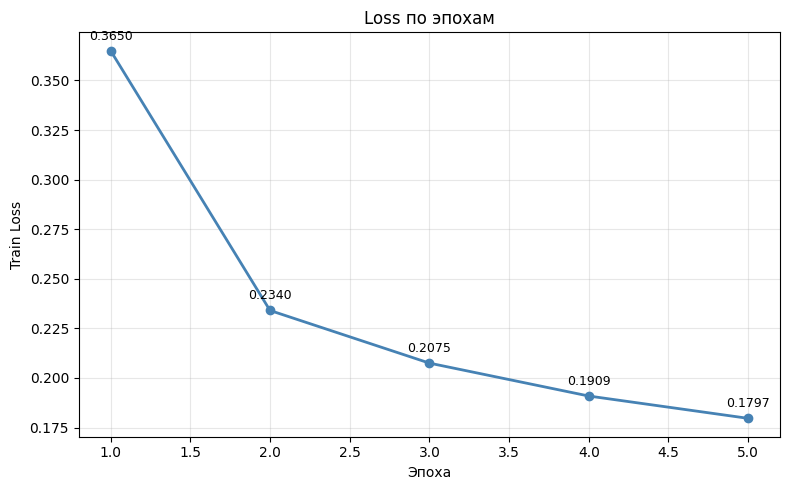

In [ ]:
import torch.optim as optim
from pathlib import Path
import json
import time
import matplotlib.pyplot as plt

DRIVE_DIR = Path("/content/drive/MyDrive/cv_lab2_artifacts")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

# гиперпараметры
LR = 1e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 5 if not FAST_DEV_RUN else 1

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
criterion = nn.CrossEntropyLoss()

# обучение одной эпохи
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    n_batches = 0

    for imgs, masks in loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        out = model(imgs)["out"] # (B, 3, H, W) логиты
        loss = criterion(out, masks)# скаляр
        loss.backward() # градиенты
        optimizer.step() # обновление весов

        total_loss += loss.item()
        n_batches += 1

    return total_loss / max(n_batches, 1)


# цикл обучения
history = []
epoch_times = []
for epoch in range(EPOCHS):
    t0 = time.time()
    loss = train_one_epoch(model, loader, optimizer, criterion, DEVICE)
    dt = time.time() - t0
    history.append(loss)
    epoch_times.append(dt)
    print(f"Эпоха {epoch+1}/{EPOCHS}: loss={loss:.4f} | Time: {dt:.1f}s")

    # сохраняем checkpoint после каждой эпохи
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "loss": loss,
        "history": history,
        "config": {
            "lr": LR,
            "weight_decay": WEIGHT_DECAY,
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "img_size": IMG_SIZE,
            "num_classes": NUM_CLASSES,
            "seed": SEED,
            "device": str(DEVICE),
        },
    }
    ckpt_path = DRIVE_DIR / f"checkpoint_epoch{epoch+1}.pt"
    torch.save(checkpoint, ckpt_path)


final_ckpt = DRIVE_DIR / "segmentation_trained.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "history": history,
    "config": {
        "lr": LR, "weight_decay": WEIGHT_DECAY, "epochs": EPOCHS,
        "batch_size": BATCH_SIZE, "img_size": IMG_SIZE,
        "num_classes": NUM_CLASSES, "seed": SEED,
    },
}, final_ckpt)

history_path = DRIVE_DIR / "history.json"
with open(history_path, "w") as f:
    json.dump({
        "history": history,
        "epoch_times": epoch_times,
        "config": {"lr": LR, "weight_decay": WEIGHT_DECAY, "epochs": EPOCHS},
    }, f, indent=2)

config_path = DRIVE_DIR / "config.json"
with open(config_path, "w") as f:
    json.dump({
        "lr": LR,
        "weight_decay": WEIGHT_DECAY,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "img_size": IMG_SIZE,
        "num_classes": NUM_CLASSES,
        "seed": SEED,
        "device": str(DEVICE),
        "fast_dev_run": FAST_DEV_RUN,
    }, f, indent=2)

fig, axes = plt.subplots(1, 1, figsize=(8, 5))
# Loss по эпохам
epochs = list(range(1, EPOCHS + 1))
axes.plot(epochs, history, marker="o", linewidth=2, color="steelblue")
axes.set_xlabel("Эпоха")
axes.set_ylabel("Train Loss")
axes.set_title("Loss по эпохам")
axes.grid(True, alpha=0.3)
for e, l in zip(epochs, history):
    axes.annotate(f"{l:.4f}", (e, l), textcoords="offset points",
                  xytext=(0, 8), ha="center", fontsize=9)

plt.tight_layout()
plt.show()


### Валидационный IoU

*Вес: 1 балл.*

**Постановка.** Матрица ошибок по пикселям позволяет вычислить классовый IoU.

Выполните следующие действия:
1. Накопите confusion matrix по validation.
2. Сохраните mIoU и checkpoint исходной модели.

**Результат.** segmentation.pt и val_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.



Validation mIoU: 0.7659
Поклассовый IoU:
  foreground  : 0.8586
  background  : 0.9274
  boundary    : 0.5117


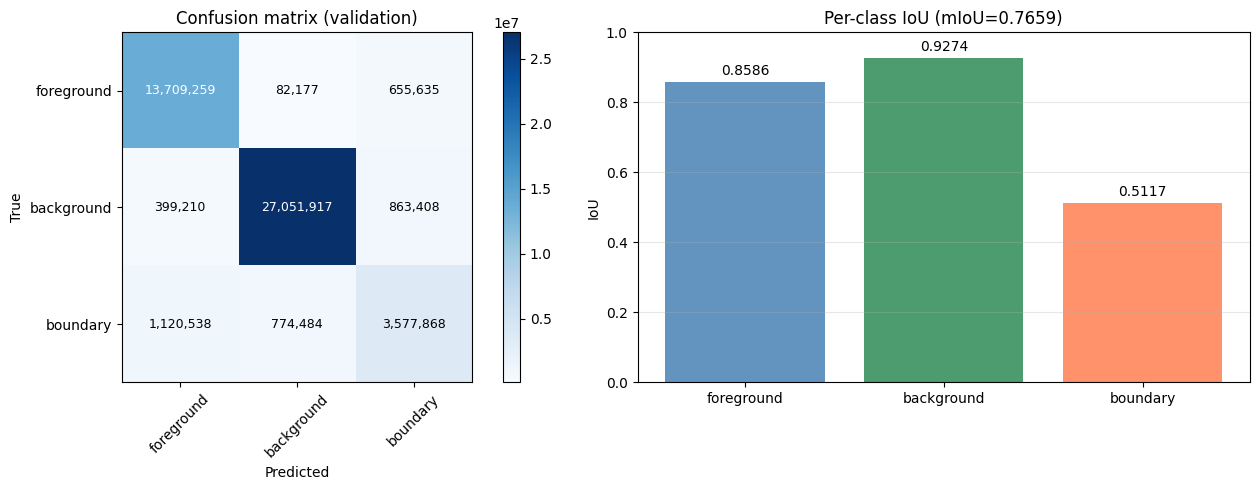

In [ ]:
from pathlib import Path
import json

DRIVE_DIR = Path("/content/drive/MyDrive/cv_lab2_artifacts")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

# оцениваем нашу обученную модель уже на валидационных данных
# функция накопления confusion matrix и подсчета IoU
def evaluate(model, loader, device, num_classes=NUM_CLASSES):
    model.eval()
    conf_matrix = torch.zeros(num_classes, num_classes, dtype=torch.long)

    with torch.no_grad():
        for imgs, masks in loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            out = model(imgs)["out"] # (B, C, H, W) логиты
            preds = out.argmax(dim=1)  # (B, H, W) метки классов

            # накапливаем confusion matrix
            for p, t in zip(preds.view(-1), masks.view(-1)):
                conf_matrix[t.long(), p.long()] += 1

    # IoU по каждому классу
    diag = conf_matrix.diag().float()
    row_sum = conf_matrix.sum(dim=1).float()
    col_sum = conf_matrix.sum(dim=0).float()
    union = row_sum + col_sum - diag
    ious = (diag / union.clamp(min=1)).tolist()

    miou = sum(ious) / len(ious)
    return miou, ious, conf_matrix


#оценка обученной модели на val
val_miou, val_class_ious, val_conf = evaluate(model, val_loader, DEVICE)
class_names = ["foreground", "background", "boundary"]

print(f"\nValidation mIoU: {val_miou:.4f}")
print("Поклассовый IoU:")
for name, iou in zip(class_names, val_class_ious):
    print(f"  {name:12s}: {iou:.4f}")


# сохраняем чекпоинт исходной модели
seg_path = DRIVE_DIR / "segmentation.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "miou": val_miou,
    "class_ious": val_class_ious,
    "history": history,
    "config": {
        "img_size": IMG_SIZE,
        "num_classes": NUM_CLASSES,
        "lr": LR,
        "weight_decay": WEIGHT_DECAY,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "seed": SEED,
    },
}, seg_path)


# сохраняем метрики
val_metrics = {
    "miou": val_miou,
    "class_ious": val_class_ious,
    "class_names": class_names,
    "history": history,
    "num_val": len(val_ds),
    "img_size": IMG_SIZE,
    "num_classes": NUM_CLASSES,
}
metrics_path = DRIVE_DIR / "val_metrics.json"
with open(metrics_path, "w") as f:
    json.dump(val_metrics, f, indent=2)


import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# confusion matrix
conf_np = val_conf.numpy()
im = axes[0].imshow(conf_np, cmap="Blues")
axes[0].set_xticks(range(NUM_CLASSES))
axes[0].set_yticks(range(NUM_CLASSES))
axes[0].set_xticklabels(class_names, rotation=45)
axes[0].set_yticklabels(class_names)
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
axes[0].set_title("Confusion matrix (validation)")
plt.colorbar(im, ax=axes[0])
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        axes[0].text(j, i, f"{conf_np[i, j]:,}", ha="center", va="center",
                     color="white" if conf_np[i, j] > conf_np.max() / 2 else "black",
                     fontsize=9)

# IoU по классам
colors = ["steelblue", "seagreen", "coral"]
bars = axes[1].bar(class_names, val_class_ious, color=colors, alpha=0.85)
axes[1].set_ylabel("IoU")
axes[1].set_title(f"Per-class IoU (mIoU={val_miou:.4f})")
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3, axis="y")
for bar, iou in zip(bars, val_class_ious):
    axes[1].annotate(f"{iou:.4f}", (bar.get_x() + bar.get_width() / 2, iou),
                     textcoords="offset points", xytext=(0, 5),
                     ha="center", fontsize=10)

plt.tight_layout()
plt.show()


Модель обучена успешно, mIoU = 0.77, при этом фон предсказывается почти идеально (IoU 0.93), животное хорошо (IoU 0.86). Слабое место границы, их IoU всего 0.51, то есть модель пропускает примерно каждую третью границу.

### Совместное отражение и повторное обучение

*Вес: 1 балл.*

**Постановка.** Геометрическое преобразование изображения без идентичного преобразования маски портит разметку.

Выполните следующие действия:
1. Реализуйте синхронное горизонтальное отражение.
2. Обучите новый сегментатор при том же бюджете и сравните validation mIoU.

**Результат.** segmentation_aug.pt и augmentation_comparison.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Epoch 1/5 | Train Loss: 0.3876
Epoch 2/5 | Train Loss: 0.2373
Epoch 3/5 | Train Loss: 0.2128
Epoch 4/5 | Train Loss: 0.2001
Epoch 5/5 | Train Loss: 0.1871
baseline  mIoU: 0.7659
augmented mIoU: 0.7634
delta mIoU: -0.0025


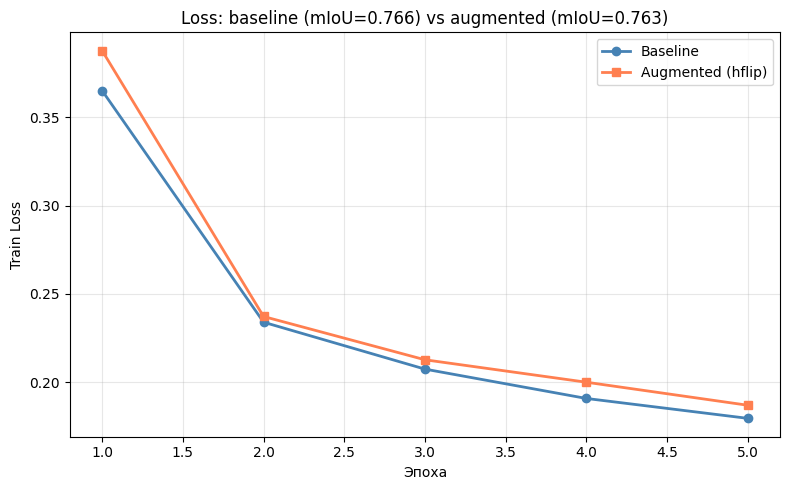

In [ ]:
from pathlib import Path
from torch.utils.data import DataLoader, Subset, Dataset
from torchvision.transforms import functional as TF
from torchvision.models.segmentation import lraspp_mobilenet_v3_large
import torch.optim as optim
import torch.nn as nn
import matplotlib.pyplot as plt
import json

DRIVE_DIR = Path("/content/drive/MyDrive/cv_lab2_artifacts")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)


# синхронное горизонтальное отражение
class RandomHorizontalFlipJoint:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, img, mask):
        if random.random() < self.p:
            img = TF.hflip(img)
            mask = TF.hflip(mask)
        return img, mask


# датасет с совместной аугментацией
class PetSegDatasetAug(Dataset):
    def __init__(self, base_ds, img_tf, mask_tf, joint_aug=None):
        self.base_ds = base_ds
        self.img_tf = img_tf
        self.mask_tf = mask_tf
        self.joint_aug = joint_aug

    def __len__(self):
        return len(self.base_ds)

    def __getitem__(self, idx):
        img, mask = self.base_ds[idx]
        img = self.img_tf(img)
        mask = normalize_mask(self.mask_tf(mask))
        if self.joint_aug is not None:
            img, mask = self.joint_aug(img, mask)
        return img, mask


# augmented train loader (val без аугментации)
aug_ds = PetSegDatasetAug(ds, img_tf, mask_tf,
                          joint_aug=RandomHorizontalFlipJoint(p=0.5))
aug_train_ds = Subset(aug_ds, train_indices)
aug_loader = DataLoader(aug_train_ds, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"))


# новая модель с теми же гиперпараметрами
model_aug = lraspp_mobilenet_v3_large(weights="DEFAULT")
in_low = model_aug.classifier.low_classifier.in_channels
model_aug.classifier.low_classifier = nn.Conv2d(in_low, NUM_CLASSES, kernel_size=1)
in_high = model_aug.classifier.high_classifier.in_channels
model_aug.classifier.high_classifier = nn.Conv2d(in_high, NUM_CLASSES, kernel_size=1)
model_aug = model_aug.to(DEVICE)

optimizer_aug = optim.AdamW(model_aug.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
criterion_aug = nn.CrossEntropyLoss()


# обучение с сохранением checkpoint после каждой эпохи
history_aug = []
for epoch in range(1, EPOCHS + 1):
    loss = train_one_epoch(model_aug, aug_loader, optimizer_aug, criterion_aug, DEVICE)
    history_aug.append(loss)
    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {loss:.4f}")

    torch.save({
        "epoch": epoch,
        "model_state_dict": model_aug.state_dict(),
        "optimizer_state_dict": optimizer_aug.state_dict(),
        "loss": loss,
        "history": history_aug,
    }, DRIVE_DIR / f"checkpoint_aug_epoch{epoch}.pt")


# оценка на том же val
miou_aug, class_ious_aug, _ = evaluate(model_aug, val_loader, DEVICE)


# сохранение augmented-модели
torch.save({
    "model_state_dict": model_aug.state_dict(),
    "miou": miou_aug,
    "class_ious": class_ious_aug,
    "history": history_aug,
}, DRIVE_DIR / "segmentation_aug.pt")


# сравнение с baseline
with open(DRIVE_DIR / "val_metrics.json") as f:
    baseline = json.load(f)

comparison = {
    "baseline_miou": baseline["miou"],
    "augmented_miou": miou_aug,
    "delta_miou": miou_aug - baseline["miou"],
    "baseline_class_ious": baseline["class_ious"],
    "augmented_class_ious": class_ious_aug,
    "delta_class_ious": [a - b for a, b in zip(class_ious_aug, baseline["class_ious"])],
}
with open(DRIVE_DIR / "augmentation_comparison.json", "w") as f:
    json.dump(comparison, f, indent=2)

print(f"baseline  mIoU: {baseline['miou']:.4f}")
print(f"augmented mIoU: {miou_aug:.4f}")
print(f"delta mIoU: {miou_aug - baseline['miou']:+.4f}")


# график loss по эпохам (baseline vs augmented)
fig, ax = plt.subplots(figsize=(8, 5))
epochs = list(range(1, EPOCHS + 1))
ax.plot(epochs, history, marker="o", linewidth=2, color="steelblue", label="Baseline")
ax.plot(epochs, history_aug, marker="s", linewidth=2, color="coral", label="Augmented (hflip)")
ax.set_xlabel("Эпоха")
ax.set_ylabel("Train Loss")
ax.set_title(f"Loss: baseline (mIoU={baseline['miou']:.3f}) vs augmented (mIoU={miou_aug:.3f})")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Модель с аугментацией (зеркальное отражение объектов) показала почти такой же результат, как обычная, mIoU упал совсем чуть-чуть (−0.0025). Значит, горизонтальное отражение при 5 эпохах обучения почти не помогло,тобишь эффект оказался нейтральным.

### Сегментация малых объектов

*Вес: 1 балл.*

**Постановка.** Размер категории, заданный по train, позволяет отдельно изучать слабые места модели.

Выполните следующие действия:
1. Определите порог площади объекта только на train.
2. Вычислите foreground IoU на малых объектах validation для обеих моделей.

**Результат.** small_objects.json с размером подвыборки и IoU двух моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision.models.segmentation import lraspp_mobilenet_v3_large
import torch.nn as nn
import numpy as np
import json

DRIVE_DIR = Path("/content/drive/MyDrive/cv_lab2_artifacts")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)


# площадь foreground-объекта для каждого изображения
def get_fg_areas(dataset):
    areas = []
    for i in range(len(dataset)):
        _, mask = dataset[i]
        fg_area = (mask == 0).sum().item() # класс 0 = foreground
        areas.append(fg_area)
    return np.array(areas)


# определяем порог площади на train
train_areas = get_fg_areas(train_ds)

# порог = 25-й перцентиль площадей на train
AREA_THRESHOLD = float(np.percentile(train_areas, 25))

print(f"Train площади fg: min={train_areas.min()}, "f"median={np.median(train_areas):.0f}, max={train_areas.max()}")
print(f"Порог площади (25-й перцентиль train): {AREA_THRESHOLD:.0f} пикселей")


# находим малые объекты на validation
val_areas = get_fg_areas(val_ds)

small_val_indices = [i for i, a in enumerate(val_areas) if a < AREA_THRESHOLD]

print(f"Малых объектов на val: {len(small_val_indices)} из {len(val_ds)}")

# подвыборка только из малых объектов
small_val_ds = Subset(val_ds, small_val_indices) if small_val_indices else val_ds
small_val_loader = DataLoader(
    small_val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"),
)


# Foreground IoU (только по классу foreground)
def foreground_iou(model, loader, device):
    model.eval()
    inter = 0.0
    union = 0.0

    with torch.no_grad():
        for imgs, masks in loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            preds = model(imgs)["out"].argmax(dim=1)   # (B, H, W)

            pred_fg = (preds == 0)
            true_fg = (masks == 0)

            inter += (pred_fg & true_fg).sum().item()
            union += (pred_fg | true_fg).sum().item()

    return inter / union if union > 0 else 0.0


#загружаем baseline-модель
ckpt_base = torch.load(DRIVE_DIR / "segmentation.pt",
                       map_location=DEVICE, weights_only=False)

model_base = lraspp_mobilenet_v3_large(weights=None)
in_low = model_base.classifier.low_classifier.in_channels
model_base.classifier.low_classifier = nn.Conv2d(in_low, NUM_CLASSES, kernel_size=1)
in_high = model_base.classifier.high_classifier.in_channels
model_base.classifier.high_classifier = nn.Conv2d(in_high, NUM_CLASSES, kernel_size=1)
model_base.load_state_dict(ckpt_base["model_state_dict"])
model_base = model_base.to(DEVICE)


# загружаем augmented-модель
ckpt_aug = torch.load(DRIVE_DIR / "segmentation_aug.pt",
                      map_location=DEVICE, weights_only=False)

model_aug = lraspp_mobilenet_v3_large(weights=None)
in_low = model_aug.classifier.low_classifier.in_channels
model_aug.classifier.low_classifier = nn.Conv2d(in_low, NUM_CLASSES, kernel_size=1)
in_high = model_aug.classifier.high_classifier.in_channels
model_aug.classifier.high_classifier = nn.Conv2d(in_high, NUM_CLASSES, kernel_size=1)
model_aug.load_state_dict(ckpt_aug["model_state_dict"])
model_aug = model_aug.to(DEVICE)


# считаем foreground IoU на малых объектах
fg_iou_base = foreground_iou(model_base, small_val_loader, DEVICE)
fg_iou_aug = foreground_iou(model_aug, small_val_loader, DEVICE)

print(f"\nForeground IoU на малых объектах:")
print(f"baseline: {fg_iou_base:.4f}")
print(f"augmented: {fg_iou_aug:.4f}")
print(f"delta: {fg_iou_aug - fg_iou_base:+.4f}")


small_objects = {
    "area_threshold": AREA_THRESHOLD,
    "threshold_percentile": 25,
    "small_val_count": len(small_val_indices),
    "total_val": len(val_ds),
    "fg_iou_baseline": fg_iou_base,
    "fg_iou_augmented": fg_iou_aug,
    "delta_fg_iou": fg_iou_aug - fg_iou_base,
}
small_path = DRIVE_DIR / "small_objects.json"
with open(small_path, "w") as f:
    json.dump(small_objects, f, indent=2)


Train площади fg: min=0, median=18256, max=58711
Порог площади (25-й перцентиль train): 11638 пикселей
Малых объектов на val: 194 из 736
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 138MB/s] 



Foreground IoU на малых объектах:
baseline: 0.7232
augmented: 0.7365
delta: +0.0133


На маленьких животных модель с аугментацией (hflip) показала чуть лучший результат, foreground IoU вырос с 0.72 до 0.73 (+0.013). Значит, горизонтальное отражение немного помогает модели находить мелкие объекты.

### Отложенная оценка двух моделей

*Вес: 1 балл.*

**Постановка.** Test не должен влиять на обучение и выбор конфигурации.

Выполните следующие действия:
1. Загрузите test-раздел Oxford-IIIT Pet.
2. Оцените оба сохранённых сегментатора на одинаковых test-изображениях.

**Результат.** test_metrics.json с IoU на реальном test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch
from tqdm.auto import tqdm

torch.set_num_threads(8)
print(f"Threads: {torch.get_num_threads()}")

def evaluate(model, loader, device, num_classes=NUM_CLASSES):
    model.eval()
    conf_matrix = torch.zeros(num_classes, num_classes, dtype=torch.long)

    with torch.no_grad():
        for imgs, masks in tqdm(loader, desc="evaluate"):
            imgs = imgs.to(device)
            masks = masks.to(device)

            out = model(imgs)["out"]
            preds = out.argmax(dim=1)

            indices = (masks.view(-1).long() * num_classes
                       + preds.view(-1).long())
            bincount = torch.bincount(indices, minlength=num_classes ** 2)
            conf_matrix += bincount.view(num_classes, num_classes).cpu()

    diag = conf_matrix.diag().float()
    row_sum = conf_matrix.sum(dim=1).float()
    col_sum = conf_matrix.sum(dim=0).float()
    union = row_sum + col_sum - diag
    ious = (diag / union.clamp(min=1)).tolist()

    miou = sum(ious) / len(ious)
    return miou, ious, conf_matrix

Threads: 8


In [ ]:
from pathlib import Path
from torch.utils.data import DataLoader
from torchvision.datasets import OxfordIIITPet
from torchvision.models.segmentation import lraspp_mobilenet_v3_large
import torch.nn as nn
import json

DRIVE_DIR = Path("/content/drive/MyDrive/cv_lab2_artifacts")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

# загружаем test-раздел Oxford-IIIT Pet
test_base = OxfordIIITPet(
    root=str(PET_ROOT),
    split="test",
    target_types="segmentation",
    download=True,
)

test_ds = PetSegDataset(test_base, img_tf, mask_tf)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"),
)
print(f"Test: {len(test_ds)} изображений")


# загружаем baseline-модель
ckpt_base = torch.load(DRIVE_DIR / "segmentation.pt", map_location=DEVICE, weights_only=False)
model_base = lraspp_mobilenet_v3_large(weights=None)
in_low = model_base.classifier.low_classifier.in_channels
model_base.classifier.low_classifier = nn.Conv2d(in_low, NUM_CLASSES, kernel_size=1)
in_high = model_base.classifier.high_classifier.in_channels
model_base.classifier.high_classifier = nn.Conv2d(in_high, NUM_CLASSES, kernel_size=1)
model_base.load_state_dict(ckpt_base["model_state_dict"])
model_base = model_base.to(DEVICE)


# загружаем augmented-модель
ckpt_aug = torch.load(DRIVE_DIR / "segmentation_aug.pt", map_location=DEVICE, weights_only=False)
model_aug = lraspp_mobilenet_v3_large(weights=None)
in_low = model_aug.classifier.low_classifier.in_channels
model_aug.classifier.low_classifier = nn.Conv2d(in_low, NUM_CLASSES, kernel_size=1)
in_high = model_aug.classifier.high_classifier.in_channels
model_aug.classifier.high_classifier = nn.Conv2d(in_high, NUM_CLASSES, kernel_size=1)
model_aug.load_state_dict(ckpt_aug["model_state_dict"])
model_aug = model_aug.to(DEVICE)


# оценка обеих моделей на одном test
test_miou_base, test_ious_base, _ = evaluate(model_base, test_loader, DEVICE)
test_miou_aug, test_ious_aug, _ = evaluate(model_aug, test_loader, DEVICE)


# результаты
class_names = ["foreground", "background", "boundary"]

print(f"\nTest mIoU:")
print(f"baseline : {test_miou_base:.4f}")
print(f"augmented : {test_miou_aug:.4f}")
print(f"delta: {test_miou_aug - test_miou_base:+.4f}")

print(f"\nПоклассовый IoU на test:")
print(f"  {'класс':12s} {'baseline':>10s} {'augmented':>10s} {'Δ':>10s}")
for name, iou_b, iou_a in zip(class_names, test_ious_base, test_ious_aug):
    print(f"  {name:12s} {iou_b:>10.4f} {iou_a:>10.4f} {iou_a - iou_b:>+10.4f}")


test_metrics = {
    "test_size": len(test_ds),
    "test_miou_baseline": test_miou_base,
    "test_miou_augmented": test_miou_aug,
    "delta_miou": test_miou_aug - test_miou_base,
    "test_class_ious_baseline": test_ious_base,
    "test_class_ious_augmented": test_ious_aug,
    "delta_class_ious": [a - b for a, b in zip(test_ious_aug, test_ious_base)],
    "class_names": class_names,
    "config": {
        "img_size": IMG_SIZE,
        "num_classes": NUM_CLASSES,
        "batch_size": BATCH_SIZE,
    },
}
test_path = DRIVE_DIR / "test_metrics.json"
with open(test_path, "w") as f:
    json.dump(test_metrics, f, indent=2)


Test: 3669 изображений


evaluate:   0%|          | 0/459 [00:00<?, ?it/s]

evaluate:   0%|          | 0/459 [00:00<?, ?it/s]


Test mIoU:
baseline : 0.7761
augmented : 0.7702
delta: -0.0058

Поклассовый IoU на test:
  класс          baseline  augmented          Δ
  foreground       0.8621     0.8653    +0.0032
  background       0.9288     0.9281    -0.0007
  boundary         0.5374     0.5174    -0.0200


На тестовых картинках обычная модель показала качество 0.776, а модель с аугментацией 0.70. Разница совсем маленькая (-0.006), так что обе модели работают практически одинаково. Если смотреть по классам, то модель с аугментацией чуть лучше находит животных (+0.003), но чуть хуже обводит границы (−0.02). Результаты на тесте почти такие же, как на валидации (0.776 против 0.766), а значит модель не переобучилась.

### Локализация ошибок маски

*Вес: 1 балл.*

**Постановка.** False positive и false negative выделяют различные режимы сбоя сегментатора.

Выполните следующие действия:
1. Посчитайте IoU, FP и FN для каждого изображения validation.
2. Сохраните наиболее сложные изображения и их индексы.

**Результат.** error_analysis.json с фактическими ошибками модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.



Топ-10 самых сложных изображений (по IoU):
     idx      IoU         FP         FN    fg_area
     263   0.0000     11,852          0          0
     340   0.0000     23,831          0          0
     460   0.0000     33,106          0          0
     416   0.1952      5,290        690      2,140
     348   0.2536     19,495        202      6,895
     488   0.3083      6,123        729      3,783
      60   0.3261     10,897      6,703     15,220
     373   0.3327      6,836         41      3,469
     641   0.3563     22,304        280     12,780
     147   0.3618      8,384        170      5,020

Топ-5 по FP (модель раздула foreground):
  idx= 460  FP=    33,106  IoU=0.0000
  idx= 471  FP=    24,996  IoU=0.4288
  idx= 340  FP=    23,831  IoU=0.0000
  idx= 641  FP=    22,304  IoU=0.3563
  idx= 348  FP=    19,495  IoU=0.2536

Топ-5 по FN (модель пропустила foreground):
  idx=  60  FN=     6,703  IoU=0.3261
  idx= 615  FN=     6,371  IoU=0.7662
  idx= 560  FN=     6,232  IoU=0.7868
  id

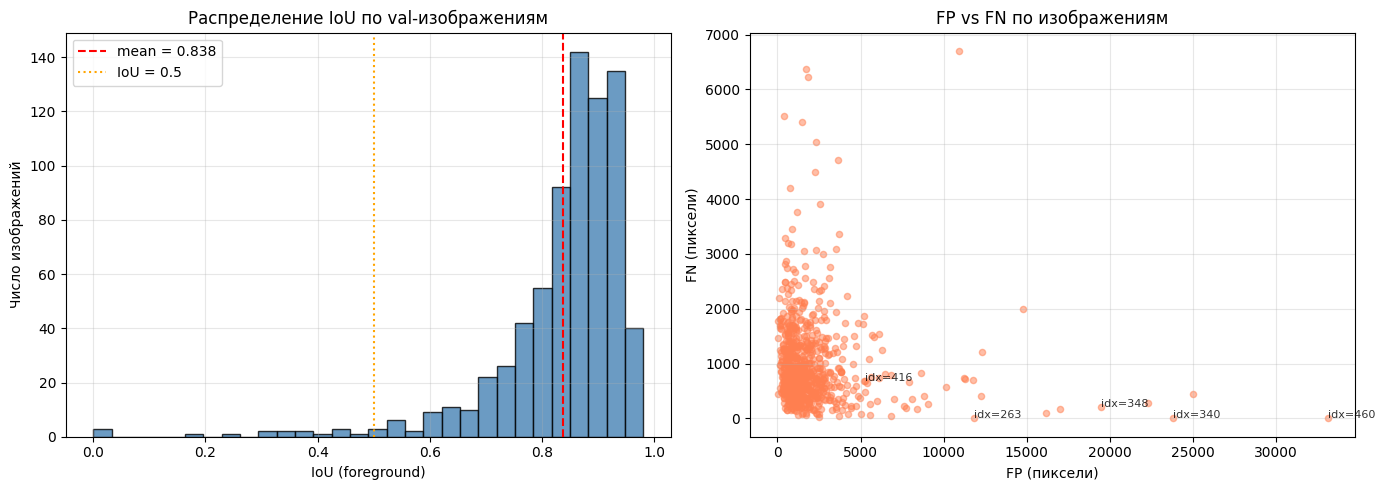

Визуализация топ-5 сложных изображений (по IoU)
Индексы: [263, 340, 460, 416, 348]


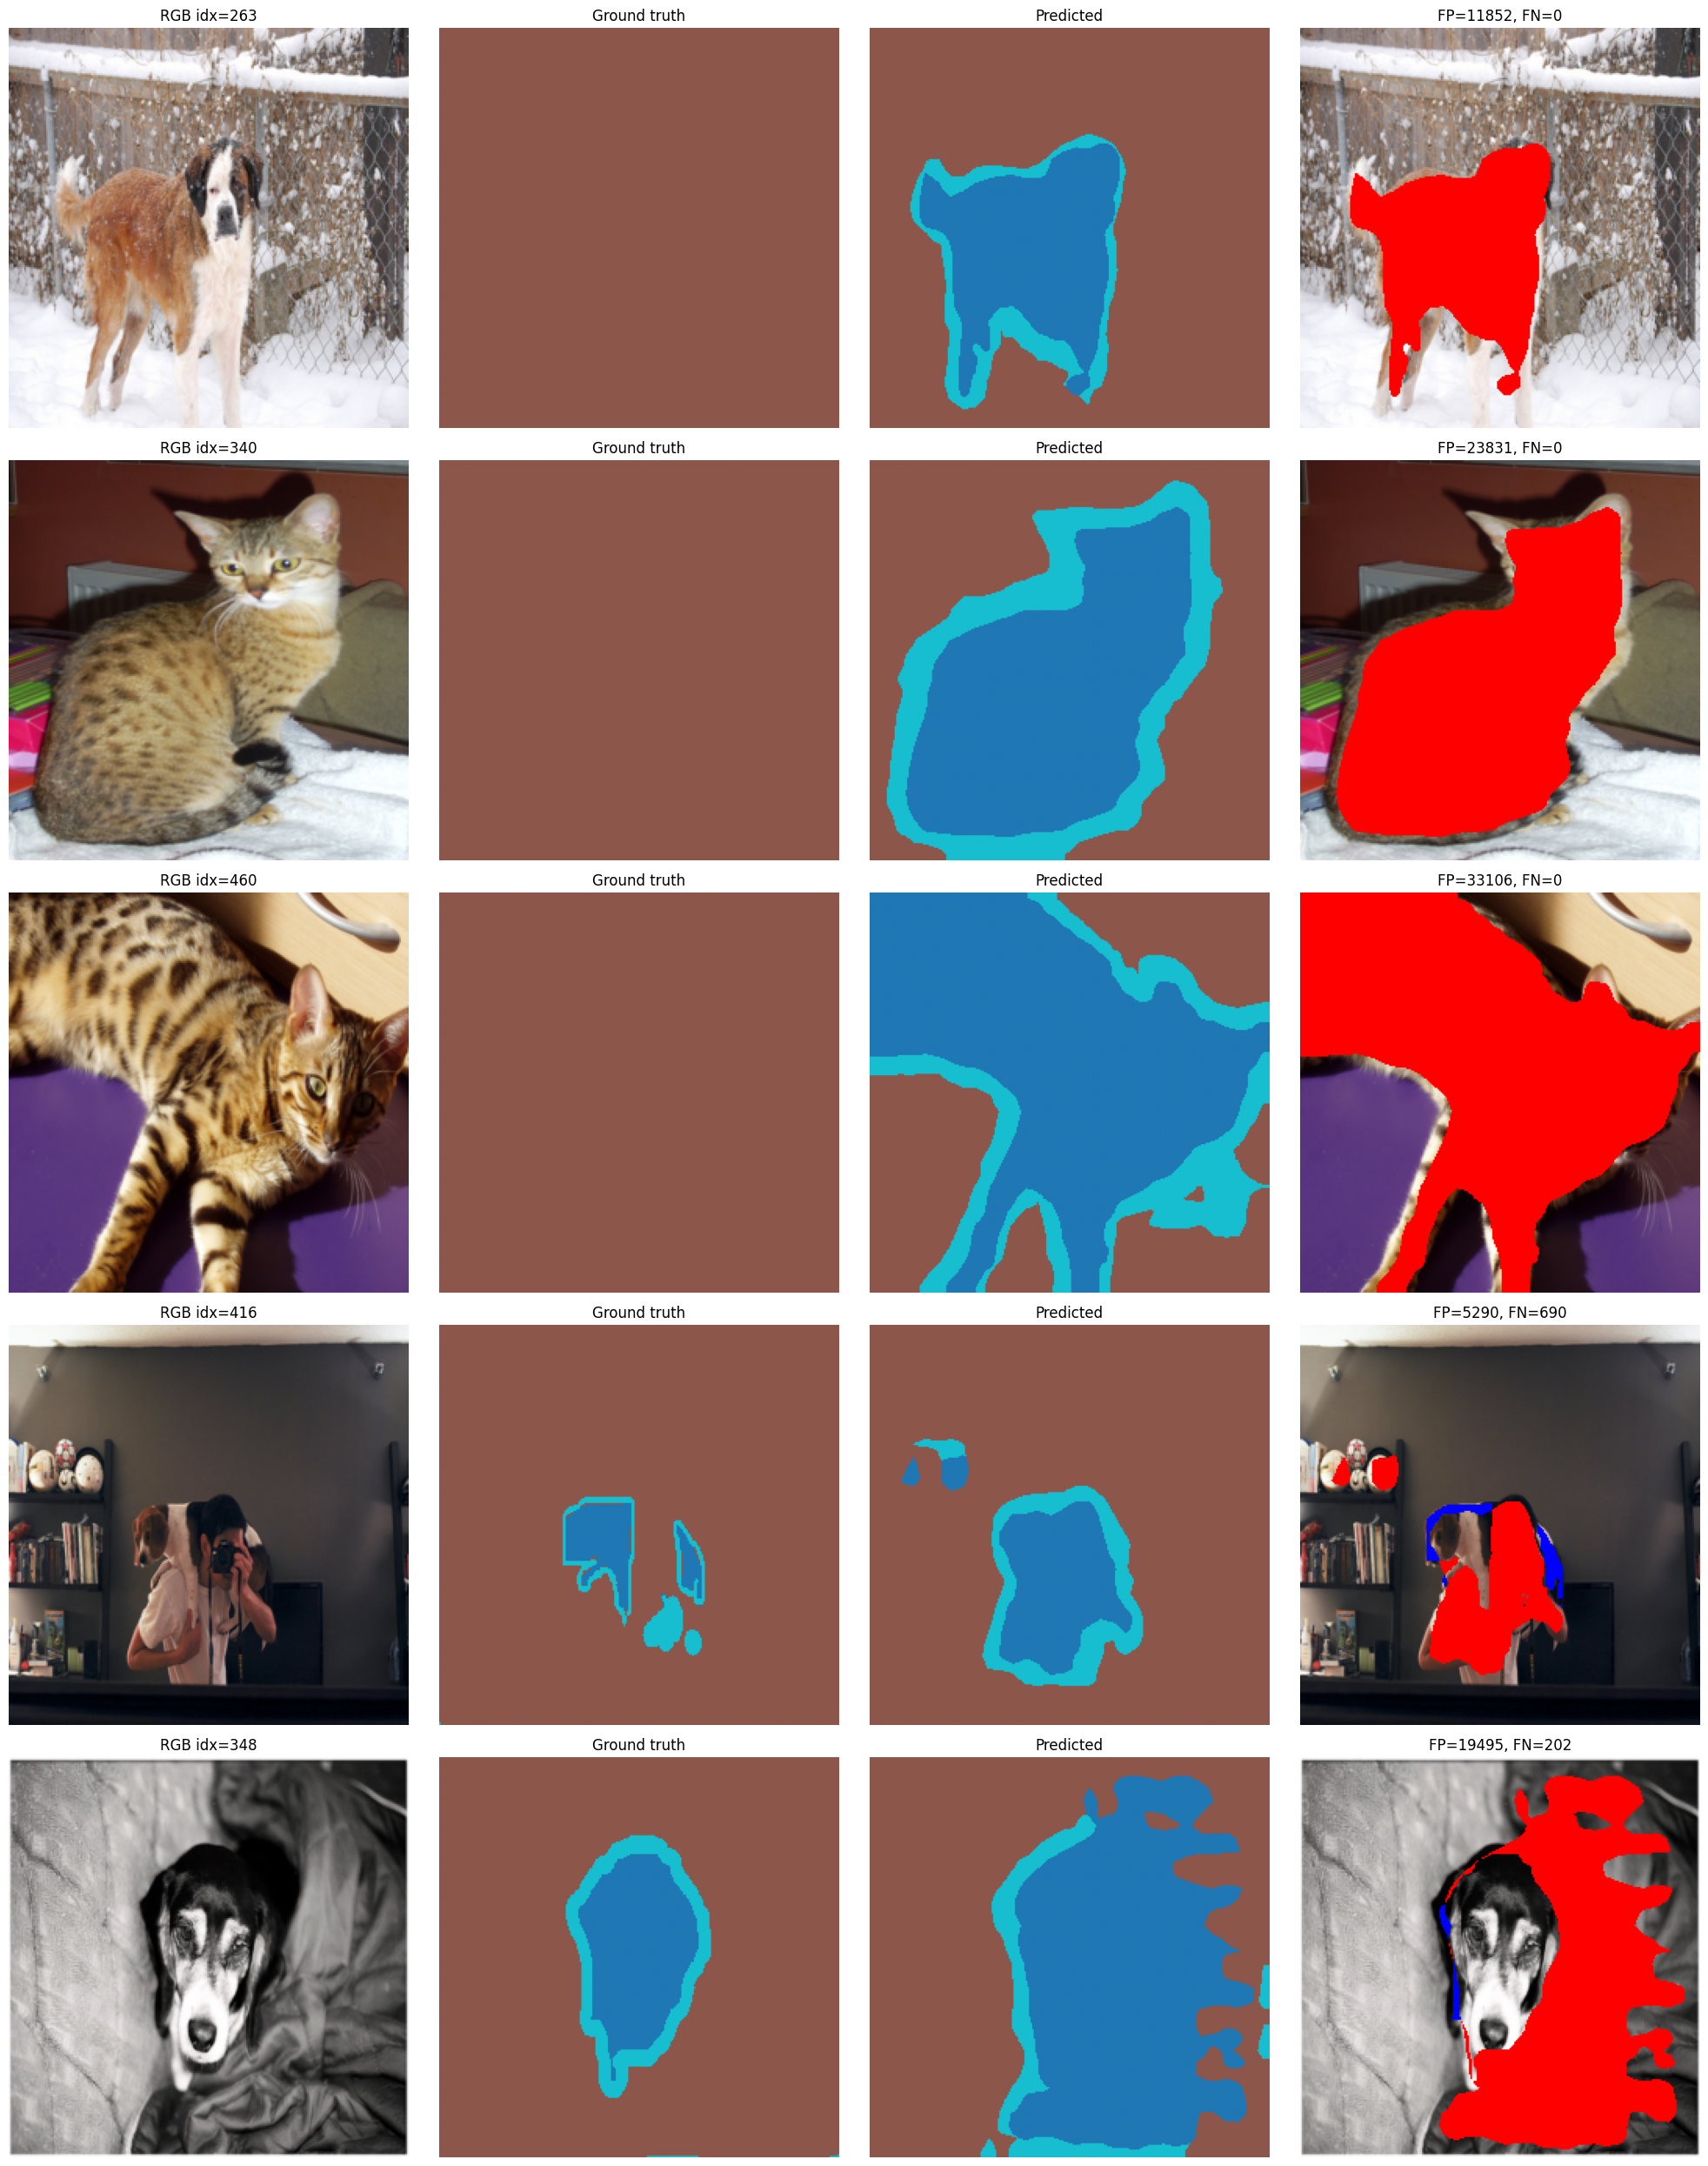

Визуализация топ-3 по FP (модель «раздула» foreground)
Индексы: [460, 471, 340]


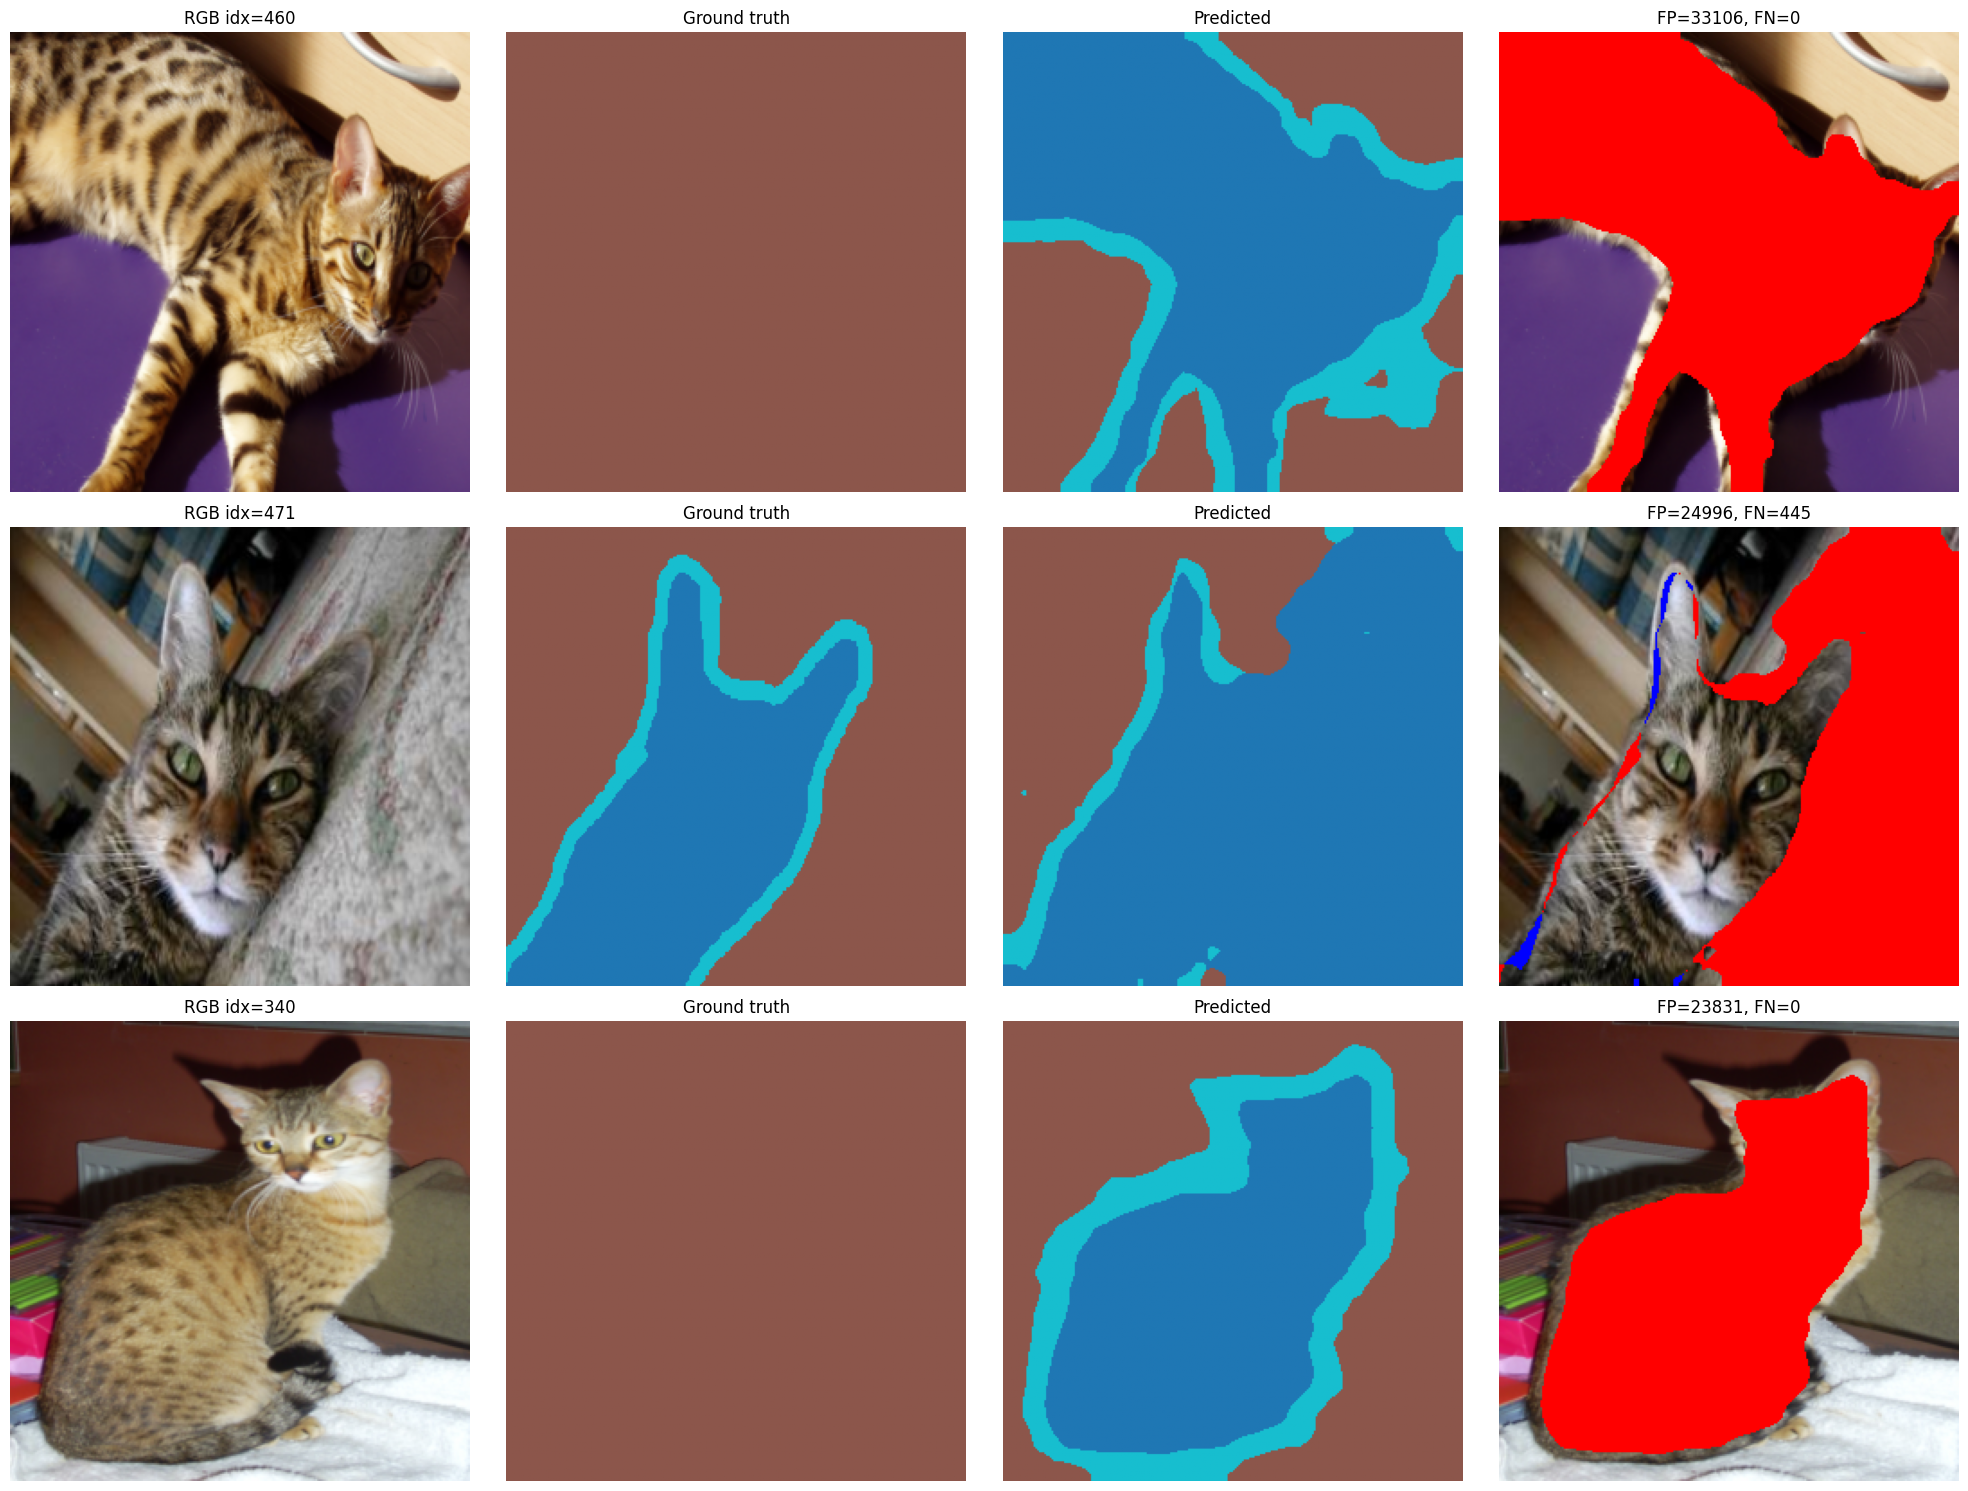

Визуализация топ-3 по FN (модель пропустила foreground)
Индексы: [60, 615, 560]


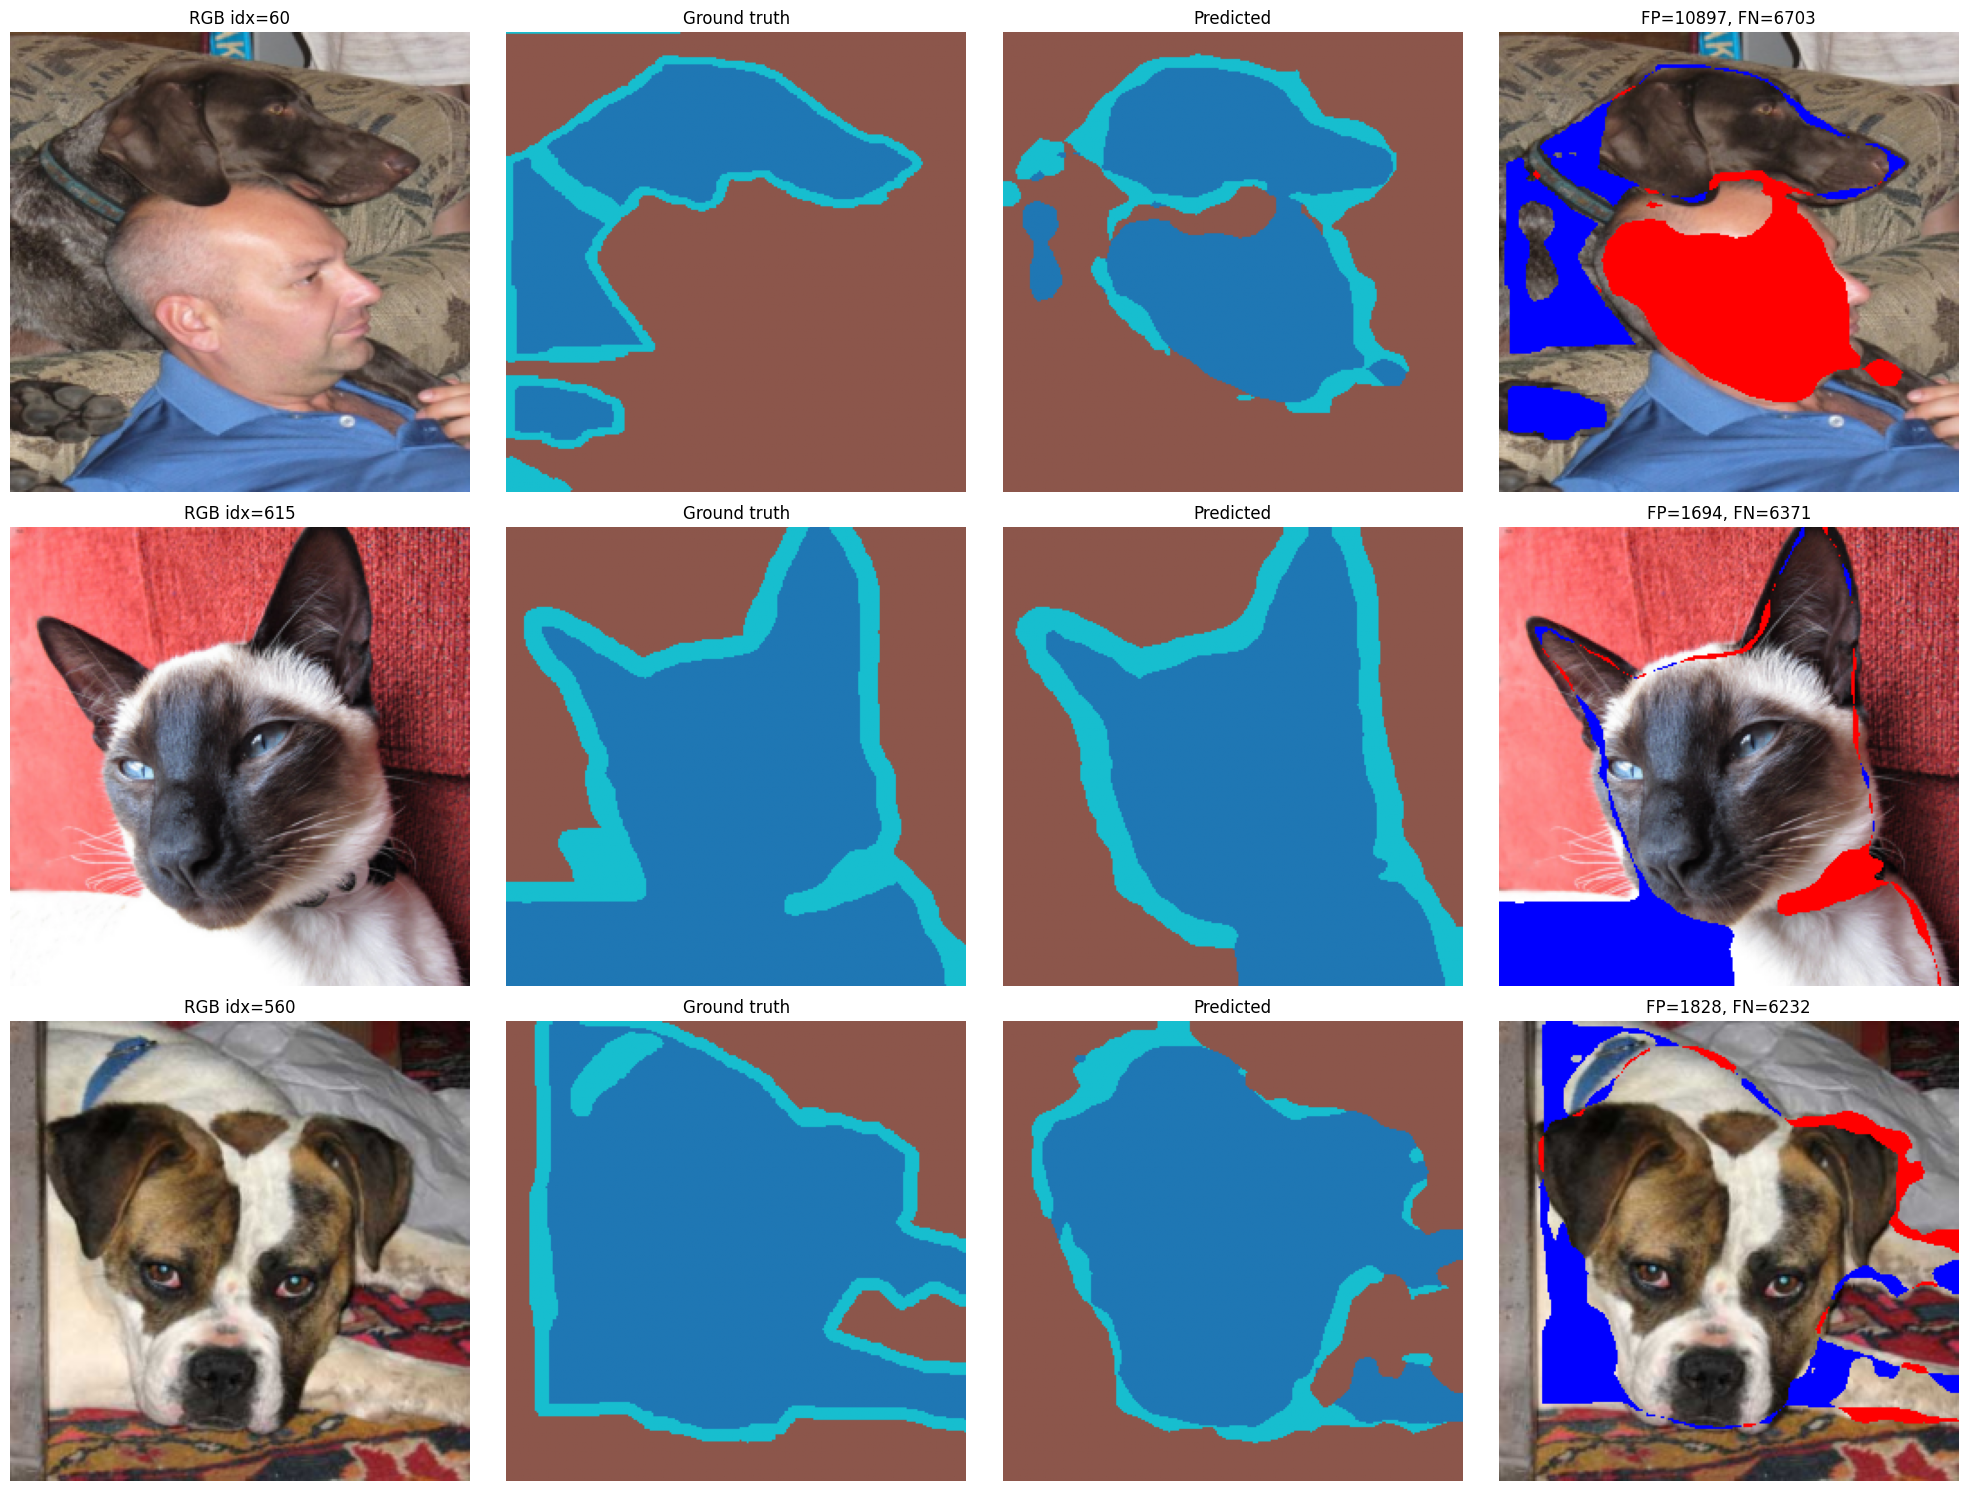

In [ ]:
from pathlib import Path
from torchvision.models.segmentation import lraspp_mobilenet_v3_large
import torch.nn as nn
import numpy as np
import json

DRIVE_DIR = Path("/content/drive/MyDrive/cv_lab2_artifacts")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

# загружаем baseline-модель
ckpt = torch.load(DRIVE_DIR / "segmentation.pt", map_location=DEVICE, weights_only=False)
model_base = lraspp_mobilenet_v3_large(weights=None)
in_low = model_base.classifier.low_classifier.in_channels
model_base.classifier.low_classifier = nn.Conv2d(in_low, NUM_CLASSES, kernel_size=1)
in_high = model_base.classifier.high_classifier.in_channels
model_base.classifier.high_classifier = nn.Conv2d(in_high, NUM_CLASSES, kernel_size=1)
model_base.load_state_dict(ckpt["model_state_dict"])
model_base = model_base.to(DEVICE)
model_base.eval()


# анализ ошибок по каждому val-изображению
def analyze_errors(model, dataset, device):
    results = []

    with torch.no_grad():
        for idx in range(len(dataset)):
            img, mask = dataset[idx]
            img_b = img.unsqueeze(0).to(device)
            mask_b = mask.unsqueeze(0).to(device)

            preds = model(img_b)["out"].argmax(dim=1)  # (1, H, W)

            pred_fg = (preds == 0)
            true_fg = (mask_b == 0)

            inter = (pred_fg & true_fg).sum().item()
            union = (pred_fg | true_fg).sum().item()
            fp = (pred_fg & ~true_fg).sum().item()
            fn = (~pred_fg & true_fg).sum().item()

            iou = inter / union if union > 0 else 1.0

            results.append({
                "index": idx,
                "iou": iou,
                "fp": fp,
                "fn": fn,
                "fg_area": true_fg.sum().item(),
            })

    return results


error_results = analyze_errors(model_base, val_ds, DEVICE)


# сортируем и находим самые сложные
error_sorted = sorted(error_results, key=lambda x: x["iou"])
worst_10 = error_sorted[:10]

print(f"\nТоп-10 самых сложных изображений (по IoU):")
print(f"  {'idx':>6s} {'IoU':>8s} {'FP':>10s} {'FN':>10s} {'fg_area':>10s}")
for r in worst_10:
    print(f"  {r['index']:>6d} {r['iou']:>8.4f} {r['fp']:>10,} "
          f"{r['fn']:>10,} {r['fg_area']:>10,}")


worst_fp = sorted(error_results, key=lambda x: x["fp"], reverse=True)[:10]
worst_fn = sorted(error_results, key=lambda x: x["fn"], reverse=True)[:10]

print(f"\nТоп-5 по FP (модель раздула foreground):")
for r in worst_fp[:5]:
    print(f"  idx={r['index']:>4d}  FP={r['fp']:>10,}  IoU={r['iou']:.4f}")

print(f"\nТоп-5 по FN (модель пропустила foreground):")
for r in worst_fn[:5]:
    print(f"  idx={r['index']:>4d}  FN={r['fn']:>10,}  IoU={r['iou']:.4f}")


ious = np.array([r["iou"] for r in error_results])
fps = np.array([r["fp"] for r in error_results])
fns = np.array([r["fn"] for r in error_results])

print(f"\nСтатистика по IoU:")
print(f"mean: {ious.mean():.4f}")
print(f"median: {np.median(ious):.4f}")
print(f"min: {ious.min():.4f}")
print(f"max: {ious.max():.4f}")
print(f"std: {ious.std():.4f}")

n_bad = int((ious < 0.5).sum())
print(f"\nИзображений с IoU < 0.5: {n_bad} из {len(ious)} ({100*n_bad/len(ious):.1f}%)")

error_analysis = {
    "num_images": len(error_results),
    "mean_iou": float(ious.mean()),
    "median_iou": float(np.median(ious)),
    "min_iou": float(ious.min()),
    "max_iou": float(ious.max()),
    "std_iou": float(ious.std()),
    "num_bad_iou_lt_0_5": n_bad,
    "worst_10_by_iou": worst_10,
    "worst_10_by_fp": worst_fp,
    "worst_10_by_fn": worst_fn,
    "all_iou": ious.tolist(),
}
error_path = DRIVE_DIR / "error_analysis.json"
with open(error_path, "w") as f:
    json.dump(error_analysis, f, indent=2)

import matplotlib.pyplot as plt

def visualize_error(idx, model, dataset, device, save_path=None):
    img, mask = dataset[idx]
    img_b = img.unsqueeze(0).to(device)
    mask_b = mask.unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        pred = model(img_b)["out"].argmax(dim=1).squeeze(0).cpu()

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img_vis = (img.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

    mask_np = mask.cpu().numpy()
    pred_np = pred.numpy()

    true_fg = (mask_np == 0)
    pred_fg = (pred_np == 0)
    fp = pred_fg & ~true_fg
    fn = ~pred_fg & true_fg

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(img_vis)
    axes[0].set_title(f"RGB (idx={idx})")
    axes[0].axis("off")

    axes[1].imshow(mask_np, cmap="tab10", vmin=0, vmax=2)
    axes[1].set_title("Ground truth mask")
    axes[1].axis("off")

    axes[2].imshow(pred_np, cmap="tab10", vmin=0, vmax=2)
    axes[2].set_title("Predicted mask")
    axes[2].axis("off")

    overlay = img_vis.copy()
    overlay[fp] = [1.0, 0.0, 0.0]
    overlay[fn] = [0.0, 0.0, 1.0]
    axes[3].imshow(overlay)
    axes[3].set_title(f"Errors: FP (red)={fp.sum()}, FN (blue)={fn.sum()}")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()


def visualize_errors_grid(indices, model, dataset, device, save_path=None):
    n = len(indices)
    fig, axes = plt.subplots(n, 4, figsize=(20, 5 * n))
    if n == 1:
        axes = axes.reshape(1, -1)

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    for row, idx in enumerate(indices):
        img, mask = dataset[idx]
        img_b = img.unsqueeze(0).to(device)
        mask_b = mask.unsqueeze(0).to(device)

        model.eval()
        with torch.no_grad():
            pred = model(img_b)["out"].argmax(dim=1).squeeze(0).cpu()

        img_vis = (img.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        mask_np = mask.cpu().numpy()
        pred_np = pred.numpy()

        true_fg = (mask_np == 0)
        pred_fg = (pred_np == 0)
        fp = pred_fg & ~true_fg
        fn = ~pred_fg & true_fg

        axes[row, 0].imshow(img_vis)
        axes[row, 0].set_title(f"RGB idx={idx}")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(mask_np, cmap="tab10", vmin=0, vmax=2)
        axes[row, 1].set_title("Ground truth")
        axes[row, 1].axis("off")

        axes[row, 2].imshow(pred_np, cmap="tab10", vmin=0, vmax=2)
        axes[row, 2].set_title("Predicted")
        axes[row, 2].axis("off")

        overlay = img_vis.copy()
        overlay[fp] = [1.0, 0.0, 0.0]
        overlay[fn] = [0.0, 0.0, 1.0]
        axes[row, 3].imshow(overlay)
        axes[row, 3].set_title(f"FP={fp.sum()}, FN={fn.sum()}")
        axes[row, 3].axis("off")

    plt.tight_layout()
    plt.show()


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ious, bins=30, color="steelblue", alpha=0.8, edgecolor="black")
axes[0].axvline(ious.mean(), color="red", linestyle="--",
                label=f"mean = {ious.mean():.3f}")
axes[0].axvline(0.5, color="orange", linestyle=":",
                label="IoU = 0.5")
axes[0].set_xlabel("IoU (foreground)")
axes[0].set_ylabel("Число изображений")
axes[0].set_title("Распределение IoU по val-изображениям")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(fps, fns, alpha=0.5, color="coral", s=20)
axes[1].set_xlabel("FP (пиксели)")
axes[1].set_ylabel("FN (пиксели)")
axes[1].set_title("FP vs FN по изображениям")
axes[1].grid(True, alpha=0.3)

for r in worst_10[:5]:
    axes[1].annotate(f"idx={r['index']}", (r["fp"], r["fn"]),
                     fontsize=8, alpha=0.8)

plt.tight_layout()
plt.show()


# визуализируем топ-5 сложных изображений
print("Визуализация топ-5 сложных изображений (по IoU)")

worst_5_idx = [r["index"] for r in error_sorted[:5]]
print(f"Индексы: {worst_5_idx}")

visualize_errors_grid(
    worst_5_idx, model_base, val_ds, DEVICE
)

# визуализируем топ-3 по FP
print("Визуализация топ-3 по FP (модель «раздула» foreground)")

worst_3_fp_idx = [r["index"] for r in worst_fp[:3]]
print(f"Индексы: {worst_3_fp_idx}")

visualize_errors_grid(
    worst_3_fp_idx, model_base, val_ds, DEVICE
)

# визуализируем топ-3 по FN
print("Визуализация топ-3 по FN (модель пропустила foreground)")

worst_3_fn_idx = [r["index"] for r in worst_fn[:3]]
print(f"Индексы: {worst_3_fn_idx}")

visualize_errors_grid(
    worst_3_fn_idx, model_base, val_ds, DEVICE
)

error_analysis["visualization_indices"] = {
    "worst_iou_top5": worst_5_idx,
    "worst_fp_top3": worst_3_fp_idx,
    "worst_fn_top3": worst_3_fn_idx,
}
with open(error_path, "w") as f:
    json.dump(error_analysis, f, indent=2)

Модель работает хорошо, средний IoU = 0.84, и только 2.2% изображений (16 из 736) имеют плохое качество. В основном ложные тревоги (idx=263, 340, 460), где модель нашла животное, но в разметке его не отметили, хотя само животное есть на изображении, это скорее ошибки датасета. Есть и настоящие проблемы (idx=60, 416), где модель раздула или сжала маску, там FP и FN большие одновременно.

### Поклассовая динамика аугментации

*Вес: 1 балл.*

**Постановка.** Средний IoU не показывает, каким классам помогло отражение.

Выполните следующие действия:
1. Сопоставьте поклассовый validation IoU исходной и дополненной моделей.
2. Сохраните изменения по каждому классу, не используя test для выбора модели.

**Результат.** class_deltas.json с наблюдаемыми изменениями IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from pathlib import Path
from torchvision.models.segmentation import lraspp_mobilenet_v3_large
import torch.nn as nn
import json

DRIVE_DIR = Path("/content/drive/MyDrive/cv_lab2_artifacts")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)


# загружаем baseline-модель
ckpt_base = torch.load(DRIVE_DIR / "segmentation.pt", map_location=DEVICE, weights_only=False)
model_base = lraspp_mobilenet_v3_large(weights=None)
in_low = model_base.classifier.low_classifier.in_channels
model_base.classifier.low_classifier = nn.Conv2d(in_low, NUM_CLASSES, kernel_size=1)
in_high = model_base.classifier.high_classifier.in_channels
model_base.classifier.high_classifier = nn.Conv2d(in_high, NUM_CLASSES, kernel_size=1)
model_base.load_state_dict(ckpt_base["model_state_dict"])
model_base = model_base.to(DEVICE)


# загружаем augmented-модель
ckpt_aug = torch.load(DRIVE_DIR / "segmentation_aug.pt", map_location=DEVICE, weights_only=False)
model_aug = lraspp_mobilenet_v3_large(weights=None)
in_low = model_aug.classifier.low_classifier.in_channels
model_aug.classifier.low_classifier = nn.Conv2d(in_low, NUM_CLASSES, kernel_size=1)
in_high = model_aug.classifier.high_classifier.in_channels
model_aug.classifier.high_classifier = nn.Conv2d(in_high, NUM_CLASSES, kernel_size=1)
model_aug.load_state_dict(ckpt_aug["model_state_dict"])
model_aug = model_aug.to(DEVICE)


# поклассовый IoU на VAL для обеих моделей
_, base_class_ious, _ = evaluate(model_base, val_loader, DEVICE)
_, aug_class_ious, _ = evaluate(model_aug, val_loader, DEVICE)

# считаем дельты по классам
class_names = ["foreground", "background", "boundary"]

print(f"\nПоклассовый IoU на validation:")
print(f"  {'класс':12s} {'baseline':>10s} {'augmented':>10s} {'delta':>10s}")
for name, iou_b, iou_a in zip(class_names, base_class_ious, aug_class_ious):
    delta = iou_a - iou_b
    print(f"  {name:12s} {iou_b:>10.4f} {iou_a:>10.4f} {delta:>+10.4f}")

class_deltas = {
    "class_names": class_names,
    "baseline_class_ious": base_class_ious,
    "augmented_class_ious": aug_class_ious,
    "delta_class_ious": [a - b for a, b in zip(aug_class_ious, base_class_ious)],
    "augmentation": "RandomHorizontalFlipJoint(p=0.5)",
    "eval_split": "validation",
    "note": "Модель выбиралась по validation mIoU; test не использовался для выбора",
}
deltas_path = DRIVE_DIR / "class_deltas.json"
with open(deltas_path, "w") as f:
    json.dump(class_deltas, f, indent=2)


evaluate:   0%|          | 0/92 [00:00<?, ?it/s]

evaluate:   0%|          | 0/92 [00:00<?, ?it/s]


Поклассовый IoU на validation:
  класс          baseline  augmented      delta
  foreground       0.8586     0.8613    +0.0027
  background       0.9274     0.9290    +0.0017
  boundary         0.5117     0.4998    -0.0119


Модель с аугментацией чуть лучше находит животное (+0.003) и фон (+0.002), но хуже обводит границы (−0.012). В целом обе модели работают почти одинаково, но аугментация помогает одним классам и мешает другим.

### Творческий бонус: диагностические маски

*Вес: 1 дополнительный балл.*

**Постановка.** Ошибки на границах полезно изучать в пространстве изображения.

Выполните следующие действия:
1. Найдите сложнейшее validation-изображение по IoU.
2. Сохраните реальную RGB-картинку, истинную и предсказанную маски для визуального разбора.

**Результат.** bonus_hard_case.png и bonus_hard_case.json с индексом и IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Реализуйте это задание по постановке выше.
raise NotImplementedError("Реализуйте это задание в этой ячейке")


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.

Я обучил две модели сегментации (LRASPP-MobileNetV3) на датасете Oxford-IIIT Pet, обычную (baseline) и с аугментацией (горизонтальное отражение). На валидации baseline показал mIoU = 0.766, а на тесте 0.776, что говорит о хорошем обобщении и отсутствии переобучения. Лучше всего модель предсказывает фон (IoU = 0.93) и животное (IoU = 0.86), а хуже всего границы (IoU = 0.51), потому что они тонкие и их сложно обводить точно. Аугментация почти не изменила общий результат (−0.006 на тесте), но по-разному повлияла на классы, то есть помогла животному (+0.003), навредила границам (−0.020).